In [1]:
!pip install qiskit qiskit-aer matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from collections import deque
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
# 0 represents the blank space

initial_state = (
    2, 5, 3,
    1, 7, 6,
    4, 8, 0
)

goal_state = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

print("Initial State:")
for i in range(0, 9, 3):
    print(initial_state[i:i+3])

print("\nGoal State:")
for i in range(0, 9, 3):
    print(goal_state[i:i+3])


# Check puzzle solvability
def count_inversions(state):

    tiles = [x for x in state if x != 0]
    inversions = 0

    for i in range(len(tiles)):
        for j in range(i + 1, len(tiles)):
            if tiles[i] > tiles[j]:
                inversions += 1

    return inversions


initial_inversions = count_inversions(initial_state)
goal_inversions = count_inversions(goal_state)

print("\nInitial inversions:", initial_inversions)
print("Goal inversions:", goal_inversions)

if initial_inversions % 2 == goal_inversions % 2:
    print("Puzzle is solvable!")
else:
    print("Puzzle is not solvable!")

Initial State:
(2, 5, 3)
(1, 7, 6)
(4, 8, 0)

Goal State:
(1, 2, 3)
(4, 5, 6)
(7, 8, 0)

Initial inversions: 8
Goal inversions: 0
Puzzle is solvable!


In [8]:
def get_neighbors(state):

    neighbors = []

    # Find blank position
    blank = state.index(0)

    row = blank // 3
    col = blank % 3

    # Possible movements
    moves = [
        (-1, 0, "UP"),
        (1, 0, "DOWN"),
        (0, -1, "LEFT"),
        (0, 1, "RIGHT")
    ]

    for dr, dc, move_name in moves:

        new_row = row + dr
        new_col = col + dc

        # Check whether move is valid
        if 0 <= new_row < 3 and 0 <= new_col < 3:

            new_position = new_row * 3 + new_col

            new_state = list(state)

            # Swap blank with adjacent tile
            new_state[blank], new_state[new_position] = (
                new_state[new_position],
                new_state[blank]
            )

            neighbors.append((tuple(new_state), move_name))

    return neighbors


print("Production rules created successfully!")

Production rules created successfully!


In [9]:
def solve_puzzle(initial, goal):

    # Queue stores states and their paths
    queue = deque([(initial, [])])

    # Track visited states
    visited = {initial}

    while queue:

        current_state, path = queue.popleft()

        # Check goal condition
        if current_state == goal:
            return path

        # Apply production rules
        for next_state, move in get_neighbors(current_state):

            if next_state not in visited:

                visited.add(next_state)

                new_path = path + [(move, next_state)]

                queue.append((next_state, new_path))

    return None


solution = solve_puzzle(initial_state, goal_state)

if solution is not None:
    print("Solution found!")
    print("Total moves:", len(solution))
else:
    print("No solution found.")

Solution found!
Total moves: 8


In [10]:
def display_state(state):

    for i in range(0, 9, 3):
        row = state[i:i+3]

        print([
            "_" if tile == 0 else tile
            for tile in row
        ])


print("INITIAL STATE")
display_state(initial_state)

for step, (move, state) in enumerate(solution, start=1):

    print("\nStep", step, "- Move:", move)

    display_state(state)

print("\nGOAL STATE REACHED!")

INITIAL STATE
[2, 5, 3]
[1, 7, 6]
[4, 8, '_']

Step 1 - Move: LEFT
[2, 5, 3]
[1, 7, 6]
[4, '_', 8]

Step 2 - Move: UP
[2, 5, 3]
[1, '_', 6]
[4, 7, 8]

Step 3 - Move: UP
[2, '_', 3]
[1, 5, 6]
[4, 7, 8]

Step 4 - Move: LEFT
['_', 2, 3]
[1, 5, 6]
[4, 7, 8]

Step 5 - Move: DOWN
[1, 2, 3]
['_', 5, 6]
[4, 7, 8]

Step 6 - Move: DOWN
[1, 2, 3]
[4, 5, 6]
['_', 7, 8]

Step 7 - Move: RIGHT
[1, 2, 3]
[4, 5, 6]
[7, '_', 8]

Step 8 - Move: RIGHT
[1, 2, 3]
[4, 5, 6]
[7, 8, '_']

GOAL STATE REACHED!


In [11]:
print("SOLUTION PATH")
print("-------------------------")

for step, (move, state) in enumerate(solution, start=1):

    print(f"Step {step}: {move}")

print("\nTotal number of moves:", len(solution))

SOLUTION PATH
-------------------------
Step 1: LEFT
Step 2: UP
Step 3: UP
Step 4: LEFT
Step 5: DOWN
Step 6: DOWN
Step 7: RIGHT
Step 8: RIGHT

Total number of moves: 8


Final blank position: 8
Binary representation: 1000

Quantum Circuit:


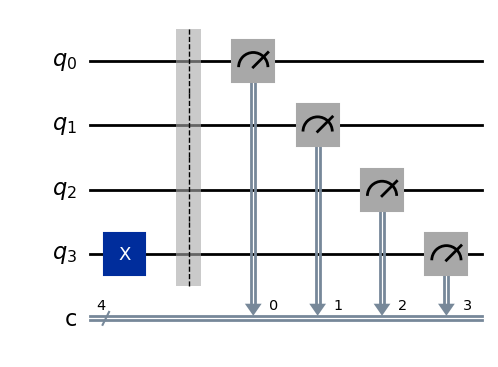

In [12]:
# Create a 4-qubit quantum circuit
qc = QuantumCircuit(4, 4)

# Final blank position
blank_position = goal_state.index(0)

# Convert position into 4-bit binary
binary_position = format(blank_position, '04b')

print("Final blank position:", blank_position)
print("Binary representation:", binary_position)

# Encode binary value into qubits
# q0 represents the least significant bit
for i in range(4):

    if binary_position[3-i] == '1':
        qc.x(i)

# Add barrier
qc.barrier()

# Measure all qubits
qc.measure(range(4), range(4))

print("\nQuantum Circuit:")
display(qc.draw(output='mpl'))

In [13]:
# Create Aer simulator
simulator = AerSimulator()

# Transpile circuit
compiled_qc = transpile(qc, simulator)

# Execute circuit
job = simulator.run(compiled_qc, shots=1000)

# Get result
result = job.result()

# Get measurement counts
counts = result.get_counts(compiled_qc)

print("Quantum Measurement Results")
print("----------------------------")
print(counts)

Quantum Measurement Results
----------------------------
{'1000': 1000}


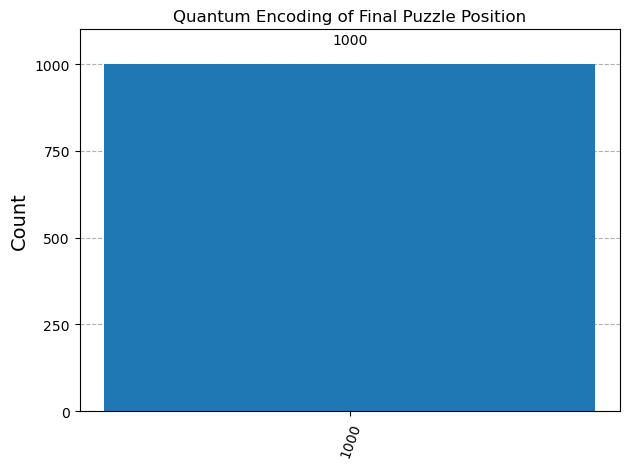

In [14]:
histogram = plot_histogram(
    counts,
    title="Quantum Encoding of Final Puzzle Position"
)

display(histogram)
plt.show()

Superposition Circuit:


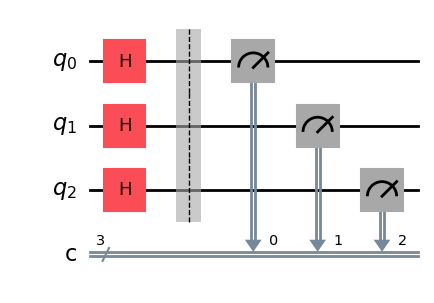


Superposition Measurement Results:
{'000': 125, '010': 141, '110': 115, '001': 120, '111': 121, '011': 139, '101': 123, '100': 116}


In [15]:
# Create a 3-qubit circuit
superposition_circuit = QuantumCircuit(3, 3)

# Apply Hadamard gates
superposition_circuit.h(0)
superposition_circuit.h(1)
superposition_circuit.h(2)

superposition_circuit.barrier()

# Measure qubits
superposition_circuit.measure(range(3), range(3))

print("Superposition Circuit:")
display(superposition_circuit.draw(output='mpl'))

# Simulate
compiled_superposition = transpile(
    superposition_circuit,
    simulator
)

job = simulator.run(
    compiled_superposition,
    shots=1000
)

superposition_result = job.result()

superposition_counts = superposition_result.get_counts(
    compiled_superposition
)

print("\nSuperposition Measurement Results:")
print(superposition_counts)

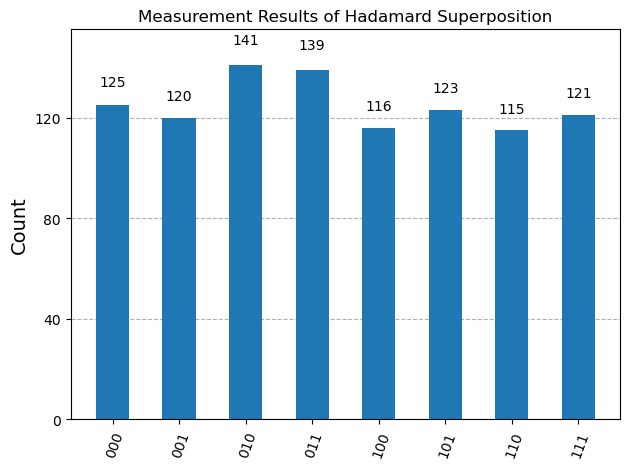

In [16]:
histogram = plot_histogram(
    superposition_counts,
    title="Measurement Results of Hadamard Superposition"
)

display(histogram)
plt.show()

In [17]:
print("EXPERIMENT 5 RESULT")
print("-------------------------------")

if solution is not None:

    print("Puzzle solved successfully!")

    print("Initial State:", initial_state)
    print("Goal State:", goal_state)

    print("Total Moves:", len(solution))

    print("Final Blank Position:", blank_position)

    print("Quantum Binary Encoding:", binary_position)

    print("\nCONCLUSION:")
    print("""
The sliding-tile puzzle was solved using a production-system
approach with BFS.

Production rules generated valid movements of the blank tile.

The algorithm reached the required goal state.

A Qiskit quantum circuit was also created to encode the final
blank position in binary and measure the quantum state.

Thus, the production-system search and quantum-state
representation were demonstrated successfully.
""")

else:
    print("Puzzle solution could not be found.")

EXPERIMENT 5 RESULT
-------------------------------
Puzzle solved successfully!
Initial State: (2, 5, 3, 1, 7, 6, 4, 8, 0)
Goal State: (1, 2, 3, 4, 5, 6, 7, 8, 0)
Total Moves: 8
Final Blank Position: 8
Quantum Binary Encoding: 1000

CONCLUSION:

The sliding-tile puzzle was solved using a production-system
approach with BFS.

Production rules generated valid movements of the blank tile.

The algorithm reached the required goal state.

A Qiskit quantum circuit was also created to encode the final
blank position in binary and measure the quantum state.

Thus, the production-system search and quantum-state
representation were demonstrated successfully.



In [ ]:
### Viva questions and answers
1. What is a production system?

A production system is a problem-solving method that uses rules to move from an initial state to a goal state.

2. What is Tarrataca's quantum production system?

It refers to a quantum approach to representing and exploring problem states using quantum operations and production rules.

3. What is the 3-puzzle problem?

It is a sliding-tile puzzle involving three numbered tiles and a blank space. The supplied program actually describes an 8-puzzle.

4. What is a state in a puzzle?

A state represents the current arrangement of tiles.

5. What is the initial state?

The starting arrangement of the puzzle.

6. What is the goal state?

The required final arrangement of tiles.

7. What are production rules?

Rules that define valid actions or movements from the current state.

8. What is BFS?

Breadth First Search explores nodes level by level.

9. Why is BFS used?

It finds a shortest solution when every move has equal cost.

10. What is a quantum bit?

A quantum bit or qubit is the basic unit of quantum information.

11. What is superposition?

Superposition allows a qubit to represent a combination of the states 0 and 1.

12. What is a Hadamard gate?

It creates an equal superposition when applied to a qubit initially in |0⟩.

13. What is a CNOT gate?

A controlled-NOT gate flips its target qubit when its control qubit is 1.

14. What is a measurement?

Measurement converts quantum information into a classical result.

15. What is QAOA?

Quantum Approximate Optimization Algorithm is a hybrid quantum-classical algorithm for optimization problems.

16. What is a quantum circuit?

A sequence of quantum gates applied to qubits.

17. What is AerSimulator?

It is a Qiskit simulator used to execute quantum circuits.

18. What is a barrier?

A barrier separates circuit operations and helps organize the circuit.

19. What is a histogram?

A histogram displays the frequency of measurement outcomes.

20. What is the difference between a classical bit and a qubit?

A classical bit is either 0 or 1, while a qubit can also exist in superposition.

Important points to remember for your viva
Term	Meaning
Initial state	Starting puzzle arrangement
Goal state	Required puzzle arrangement
Production rules	Valid tile movements
BFS	Searches level by level
Qubit	Quantum information unit
Hadamard	Creates superposition
Measurement	Reads quantum result
AerSimulator	Simulates quantum circuits
Histogram	Shows measurement frequencies

One important viva clarification: The assignment's original QAOA code is not a valid implementation as written: its objective function and mixer are not correctly integrated into the QAOA interface, and its old Aqua imports are obsolete. The practical above gives you a working puzzle solver and a separate Qiskit demonstration. Don't claim that the BFS section is itself a quantum speedup.

For your viva, the most important distinction is understanding the puzzle's production rules, how BFS reaches the goal, and what the quantum circuit's measured 1000 represents.